# Prueba individual · Sesión 03
### Career Tech Hub · Un caso de datos de principio a fin

**Nombre:** *Fabiola Altamirano Alfaro*

Trabajas con los mismos datos de la sesión. Lee antes el PDF de la prueba: ahí están las instrucciones y la rúbrica.

- Haz **al menos dos** de las partes A (pandas), B (SQL) y C (Excel o Power BI).
- La **parte D es obligatoria**.
- Este cuaderno tiene que estar en la misma carpeta que el cuaderno de la sesión, junto a la carpeta `datos`.

In [25]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import HTML, display

rutaexcel = "/Users/fabiolaaltamirano/Sesion 3/Data/electricidad_para_panel.xlsx"
rutabbdd = "/Users/fabiolaaltamirano/Sesion 3/Data/electricidad.db"

# Las hojas del Excel (para la parte A)
dias = pd.read_excel(rutaexcel, sheet_name="dias")
generacion = pd.read_excel(rutaexcel, sheet_name="generacion")



# La base de datos (para la parte B)
conexion = sqlite3.connect(rutabbdd)

def sql(consulta):
    # Lanza una consulta y devuelve el resultado como tabla de pandas.
    return pd.read_sql(consulta, conexion)

print("Hoja dias:", dias.shape[0], "filas ·", list(dias.columns))
sql("SELECT type AS tipo, name AS nombre FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

Hoja dias: 1415 filas · ['fecha', 'dia_semana', 'mes', 'festivo', 'descanso', 't_med', 'demanda_gwh', 'año']


,tipo,nombre
0,table,ciudades
1,table,demanda
2,table,festivos
3,table,generacion
4,table,predicciones
5,table,tiempo
6,view,tabla_dias
7,view,temperatura_nacional


Columnas de las tablas de la base de datos:

| Tabla | Columnas |
|---|---|
| `demanda` | `fecha`, `demanda_gwh` |
| `generacion` | `fecha`, `tecnologia`, `tipo`, `gwh` |
| `tiempo` | `fecha`, `ciudad`, `t_max`, `t_min`, `t_med`, `lluvia_mm`, `viento_kmh`, `sol_mj` |
| `ciudades` | `ciudad`, `latitud`, `longitud`, `habitantes` |
| `festivos` | `fecha`, `festivo` |
| `temperatura_nacional` (vista) | `fecha`, `t_med` |
| `tabla_dias` (vista) | `fecha`, `demanda_gwh`, `t_med`, `festivo`, `demanda_ayer`, `demanda_hace_7` |

# Parte A · pandas

Usa la tabla `dias`.

**A1.** ¿Cuántos días superaron los 800 GWh de demanda? ¿Cuántos fueron en cada año?

Total de días que superan los 800 GWh: 115
    año  dias_superan_800
0  2023                16
1  2024                10
2  2025                25
3  2026                64


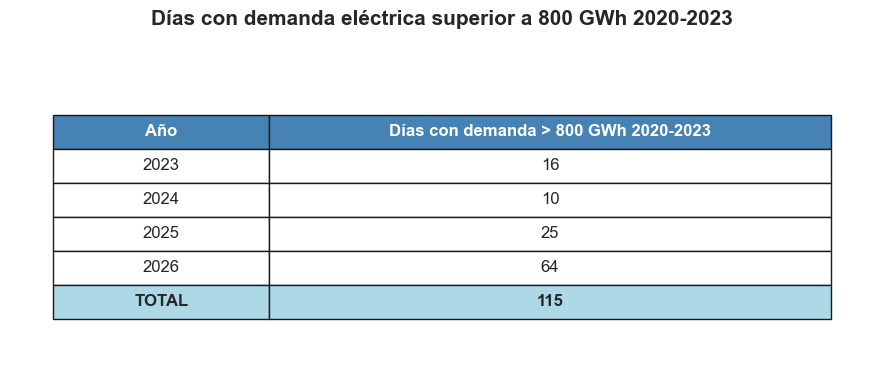

In [26]:
# 1. Filtrar los días que superan los 800 GWh
dias_sup = dias[dias["demanda_gwh"] > 800]

# 2. Días por año (se crea primero por_anio)
por_anio = (
    dias_sup
    .groupby("año")
    .size()
    .rename("dias_superan_800")
    .reset_index()
)

# 3. Total de días (ahora por_anio ya existe)
total_dias = por_anio["dias_superan_800"].sum()
print("Total de días que superan los 800 GWh:", total_dias)

# 4. Mostrar los días por año
print(por_anio)

total_dias = por_anio["dias_superan_800"].sum()

# 2. Añadir la fila TOTAL
tabla_dias = pd.concat([
    por_anio,
    pd.DataFrame({
        "año": ["TOTAL"],
        "dias_superan_800": [total_dias]
    })
], ignore_index=True)

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(9, 4))
ax.axis("off")

tabla = ax.table(
    cellText=tabla_dias.values,
    colLabels=[
        "Año",
        "Días con demanda > 800 GWh 2020-2023"
    ],
    cellLoc="center",
    loc="center",
    colWidths=[0.25, 0.65]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(12)
tabla.scale(1, 2)

for col in range(2):
    tabla[(0, col)].set_facecolor("steelblue")
    tabla[(0, col)].set_text_props(
        color="white",
        weight="bold"
    )

ultima_fila = len(tabla_dias)

for col in range(2):
    tabla[(ultima_fila, col)].set_facecolor("lightblue")
    tabla[(ultima_fila, col)].set_text_props(
        weight="bold"
    )

ax.set_title(
    "Días con demanda eléctrica superior a 800 GWh 2020-2023",
    fontsize=15,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()



<h2 style="font-size: 22px;">B3. Interpretación de los días con demanda eléctrica superior a 800 GWh (2023-2026).</h2>

<p style="font-size: 20px;">
La tabla muestra una evolución irregular de los días con demanda eléctrica superior a 800 GWh, alcanzando su máximo en 2026, con 64 días. Esta cifra supera ampliamente los registros de años anteriores y representa más de la mitad del total acumulado (115 días). Se observa, por tanto, un incremento significativo de los días de alta demanda eléctrica.
</p>


**A2.** Haz una tabla con la demanda media de cada año, separando los días laborables de los días de descanso (columna `descanso`). ¿Qué porcentaje menos se gasta en un día de descanso, cada año?


DEMANDA MEDIA POR AÑO Y TIPO DE DÍA
descanso  demanda_laborable  demanda_descanso  porcentaje_menos
año                                                            
2023                 707.72            605.50             14.44
2024                 710.06            612.02             13.81
2025                 732.49            633.23             13.55
2026                 749.86            643.03             14.25
descanso   Año  Demanda media laborables (GWh)  Demanda media descanso (GWh)  \
0         2023                          707.72                        605.50   
1         2024                          710.06                        612.02   
2         2025                          732.49                        633.23   
3         2026                          749.86                        643.03   

descanso  Reducción (%)  
0                 14.44  
1                 13.81  
2                 13.55  
3                 14.25  


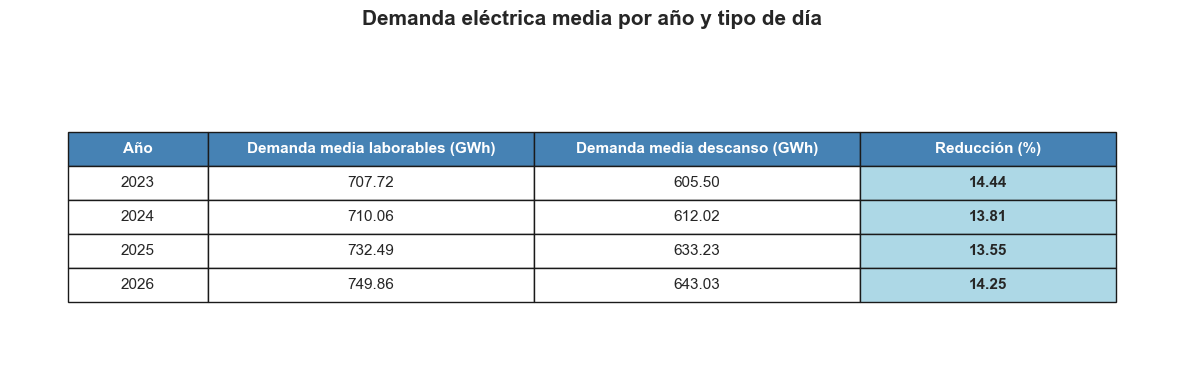

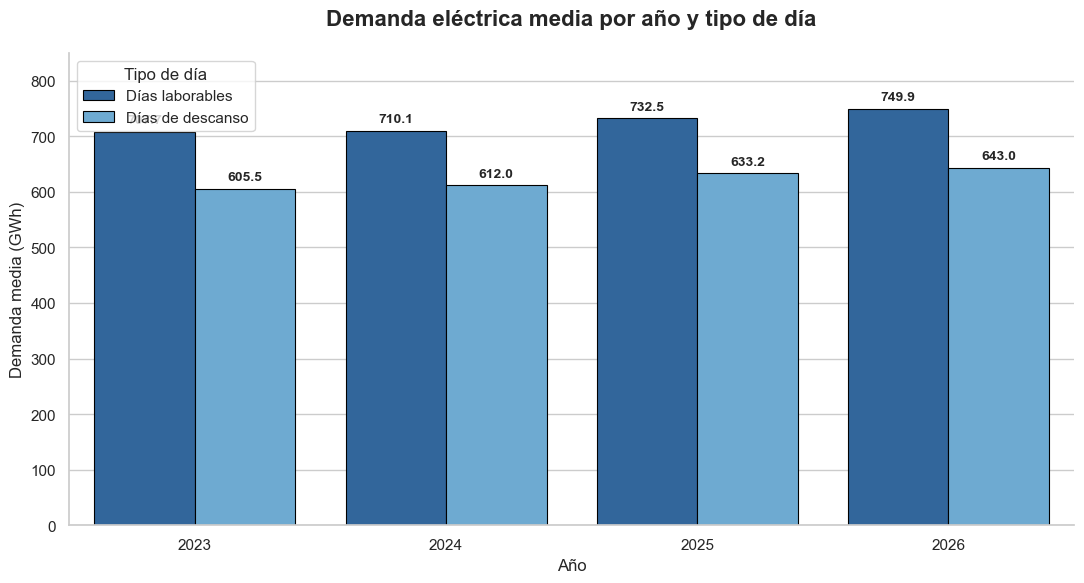

In [27]:
demanda_media = (
    dias.groupby(["año", "descanso"])["demanda_gwh"]
    .mean()).round(2)

demanda_anual = demanda_media.unstack()

demanda_anual = demanda_anual.rename(
    columns={
        False: "demanda_laborable", 
        True: "demanda_descanso"})

demanda_anual["porcentaje_menos"] = (
    (demanda_anual["demanda_laborable"]
     - demanda_anual["demanda_descanso"])
    / demanda_anual["demanda_laborable"]
) * 100

demanda_anual = demanda_anual.round(2)

print("\nDEMANDA MEDIA POR AÑO Y TIPO DE DÍA")
print(demanda_anual)



# 1. Crear una copia de los resultados
tabla_a2 = demanda_anual.reset_index().copy()


# 3. Cambiar los nombres de las columnas
tabla_a2 = tabla_a2.rename(columns={
    "año": "Año",
    "demanda_laborable": "Demanda media laborables (GWh)",
    "demanda_descanso": "Demanda media descanso (GWh)",
    "porcentaje_menos": "Reducción (%)"
})

print(tabla_a2)
# 4. Configurar estilo
sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis("off")

# 5. Crear tabla

texto_celdas = tabla_a2.copy()
texto_celdas["Año"] = texto_celdas["Año"].astype(int).astype(str)

for col in texto_celdas.columns[1:]:
    texto_celdas[col] = texto_celdas[col].map("{:.2f}".format)


tabla = ax.table(
    cellText=texto_celdas.values,        
    colLabels=tabla_a2.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.12, 0.28, 0.28, 0.22]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1, 2)



# 6. Personalizar encabezados
for col in range(len(tabla_a2.columns)):
    tabla[(0, col)].set_facecolor("steelblue")
    tabla[(0, col)].set_text_props(
        color="white",
        weight="bold"
    )

# 7. Destacar la reducción
for fila in range(1, len(tabla_a2) + 1):
    tabla[(fila, 3)].set_facecolor("lightblue")
    tabla[(fila, 3)].set_text_props(weight="bold")

# 8. Título
ax.set_title(
    "Demanda eléctrica media por año y tipo de día",
    fontsize=15,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()

# Pasar la tabla a formato largo para el gráfico de barras
demanda_grafico = (
    demanda_anual[["demanda_laborable", "demanda_descanso"]]
    .reset_index()
    .melt(id_vars="año", var_name="tipo_dia", value_name="demanda_media")
)

# 1. Configurar estilo
sns.set_theme(style="whitegrid")

# 2. Cambiar los nombres de las categorías
demanda_grafico["tipo_dia"] = demanda_grafico["tipo_dia"].replace({
    "demanda_laborable": "Días laborables",
    "demanda_descanso": "Días de descanso"
})

# 3. Crear gráfico
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=demanda_grafico,
    x="año",
    y="demanda_media",
    hue="tipo_dia",
    hue_order=["Días laborables", "Días de descanso"],
    palette={
        "Días laborables": "#2166AC",
        "Días de descanso": "#5DADE2"
    },
    edgecolor="black",
    linewidth=0.8,
    ax=ax
)

# 4. Añadir valores encima de las barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

# 5. Personalizar título y ejes
ax.set_title(
    "Demanda eléctrica media por año y tipo de día",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Demanda media (GWh)", fontsize=12)

# 6. Mejorar leyenda
ax.legend(
    title="Tipo de día",
    loc="upper left",
    frameon=True
)

# 7. Ajustar presentación
ax.set_ylim(0, 850)
sns.despine()
plt.tight_layout()
plt.show()



<h2 style="font-size: 22px;">Respuesta A2.</h2>

<p style="font-size: 20px;">
La demanda eléctrica media es inferior durante los días de descanso en todos los años analizados.

La reducción respecto a los días laborables se sitúa aproximadamente entre el 13,56 % y el 14,48 %. El mayor descenso porcentual se produce en 2023 (14,48 %), mientras que el menor corresponde a 2025 (13,56 %).

También se observa que la demanda media aumenta progresivamente entre 2023 y 2026 tanto en los días laborables como en los días de descanso.

Esta diferencia puede explicarse por la menor actividad industrial, comercial y laboral durante los días de descanso.
</p>


**A3.** ¿Cuál fue el mes con mayor demanda media de los cuatro años (di el mes y el año)? ¿Y el de menor?

Mayor demanda media: mes 7 de 2026 -> 814.83 GWh
Menor demanda media: mes 4 de 2023 -> 610.56 GWh


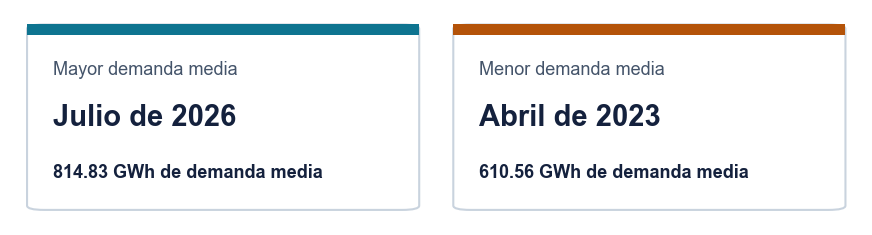

In [28]:
mensual = (
    dias.groupby(["año", "mes"])["demanda_gwh"]
      .mean()
      .round(2)
      .rename("demanda_media")
      .reset_index()
)

# 3. Mes con mayor y menor demanda media
mes_max = mensual.loc[mensual["demanda_media"].idxmax()]
mes_min = mensual.loc[mensual["demanda_media"].idxmin()]

print(f"Mayor demanda media: mes {int(mes_max['mes'])} de {int(mes_max['año'])} "
      f"-> {mes_max['demanda_media']} GWh")
print(f"Menor demanda media: mes {int(mes_min['mes'])} de {int(mes_min['año'])} "
      f"-> {mes_min['demanda_media']} GWh")

# 3. Nombres de los meses (la tabla trae el número)
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
         "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

def nombre_mes(fila):
    return f"{MESES[int(fila['mes']) - 1]} de {int(fila['año'])}"

# 4. Tarjetas KPI dibujadas con matplotlib
def dibujar_tarjeta(ax, x, titulo, fila, color):
    ancho, alto = 0.46, 0.86

    ax.add_patch(FancyBboxPatch(
        (x, 0.07), ancho, alto,
        boxstyle="round,pad=0,rounding_size=0.02",
        facecolor="white",
        edgecolor="#c9d3de",
        linewidth=1.5,
        transform=ax.transAxes
    ))

    ax.add_patch(Rectangle(
        (x, 0.07 + alto - 0.05), ancho, 0.05,
        facecolor=color,
        edgecolor="none",
        transform=ax.transAxes
    ))

    ax.text(
        x + 0.03, 0.70, titulo,
        fontsize=13, color="#44546a",
        transform=ax.transAxes
    )

    ax.text(
        x + 0.03, 0.46, nombre_mes(fila).capitalize(),
        fontsize=21, fontweight="bold",
        color="#14213d",
        transform=ax.transAxes
    )

    ax.text(
        x + 0.03, 0.22,
        f"{fila['demanda_media']:.2f} GWh de demanda media",
        fontsize=13, fontweight="bold",
        color="#14213d",
        transform=ax.transAxes
    )


fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis("off")

dibujar_tarjeta(ax, 0.02, "Mayor demanda media", mes_max, "#0e7490")
dibujar_tarjeta(ax, 0.52, "Menor demanda media", mes_min, "#b45309")

# Guardar la imagen antes de mostrarla
fig.savefig("kpi_a3.png", dpi=150, bbox_inches="tight")

# Mostrar las tarjetas en el notebook
plt.show()


# Parte B · SQL

Usa la función `sql("...")` con la base de datos.

**B1.** Saca los cinco días más calurosos (vista `temperatura_nacional`) junto con su demanda. ¿Son también días de mucha demanda? Explica por qué en una o dos frases.

       fecha  t_med  demanda_gwh
0 2023-08-23  31.61   805.114493
1 2025-06-29  31.43   707.452281
2 2025-08-11  31.49   770.154701
3 2025-08-16  31.81   712.442720
4 2025-08-17  31.79   698.786118


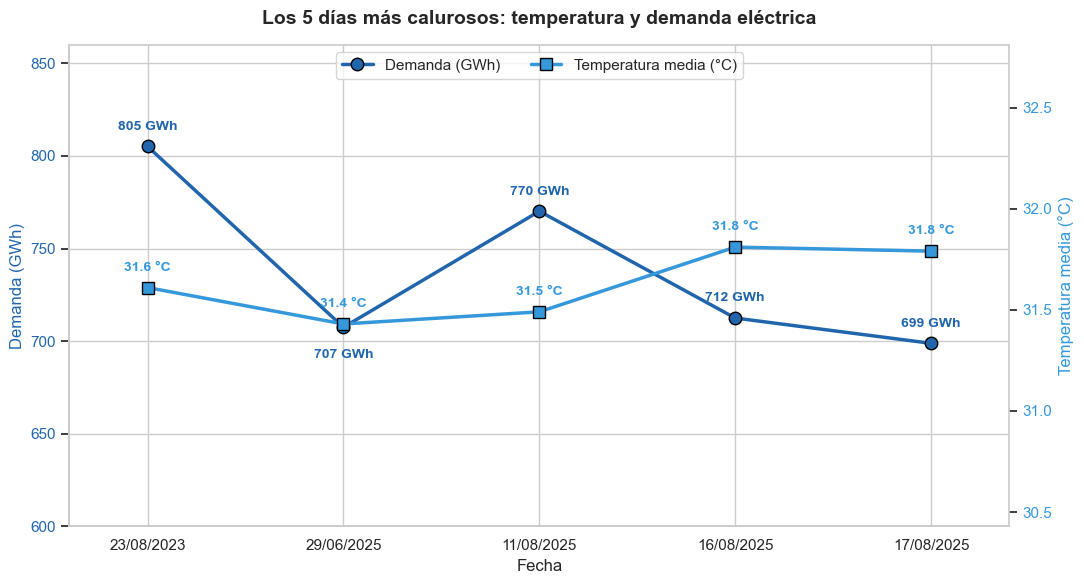

In [29]:
conexion = sqlite3.connect(rutabbdd)
# 1. Obtener los 5 días más calurosos y su demanda eléctrica
consulta = """
SELECT t.fecha, t.t_med, d.demanda_gwh
FROM temperatura_nacional AS t
INNER JOIN demanda AS d ON d.fecha = t.fecha
WHERE t.t_med IS NOT NULL
  AND d.demanda_gwh IS NOT NULL
ORDER BY t.t_med DESC
LIMIT 5;
"""

top5 = pd.read_sql_query(consulta, conexion)
conexion.close()

# 2. Comprobar que existen resultados
if top5.empty:
    print("La consulta no ha devuelto resultados.")
else:

    # Convertir fecha y ordenar cronológicamente
    top5["fecha"] = pd.to_datetime(top5["fecha"])
    top5 = top5.sort_values("fecha").reset_index(drop=True)

    print(top5)

    # 3. Preparar el eje X
    x = list(range(len(top5)))
    etiquetas = top5["fecha"].dt.strftime("%d/%m/%Y").tolist()

    # 4. Crear gráfico
    sns.set_theme(style="whitegrid")
    fig, ax1 = plt.subplots(figsize=(11, 6))

    # DEMANDA ELÉCTRICA (eje izquierdo)
    ax1.plot(
        x, top5["demanda_gwh"],
        color="#2166AC",
        linewidth=2.5,
        marker="o",
        markersize=9,
        markeredgecolor="black",
        label="Demanda (GWh)"
    )

    ax1.set_ylabel("Demanda (GWh)", color="#2166AC", fontsize=12)
    ax1.tick_params(axis="y", labelcolor="#2166AC")
    ax1.set_ylim(600, 860)

    # Etiquetas de demanda
    dem = top5["demanda_gwh"].tolist()

    for i, valor in enumerate(dem):
        vecinos = [dem[j] for j in (i - 1, i + 1) if 0 <= j < len(dem)]
        abajo = len(vecinos) == 2 and all(valor < v for v in vecinos)

        ax1.annotate(
            f"{valor:.0f} GWh",
            (x[i], valor),
            textcoords="offset points",
            xytext=(0, -22 if abajo else 12),
            ha="center",
            fontsize=10,
            fontweight="bold",
            color="#2166AC"
        )

    # TEMPERATURA (eje derecho)
    ax2 = ax1.twinx()

    ax2.plot(
        x, top5["t_med"],
        color="#3498DB",
        linewidth=2.5,
        marker="s",
        markersize=9,
        markeredgecolor="black",
        label="Temperatura media (°C)"
    )

    ax2.set_ylabel("Temperatura media (°C)", color="#3498DB", fontsize=12)
    ax2.tick_params(axis="y", labelcolor="#3498DB")
    ax2.grid(False)

    # Ajustar límites del eje de temperatura
    minimo = top5["t_med"].min()
    maximo = top5["t_med"].max()
    margen = max((maximo - minimo) * 0.25, 1)

    ax2.set_ylim(minimo - margen, maximo + margen)

    # Etiquetas de temperatura
    for i, valor in enumerate(top5["t_med"]):
        ax2.annotate(
            f"{valor:.1f} °C",
            (x[i], valor),
            textcoords="offset points",
            xytext=(0, 12),
            ha="center",
            fontsize=10,
            fontweight="bold",
            color="#3498DB"
        )

    # 5. Fechas en el eje X
    ax1.set_xticks(x)
    ax1.set_xticklabels(etiquetas, fontsize=11)
    ax1.set_xlabel("Fecha", fontsize=12)
    ax1.set_xlim(-0.4, len(x) - 0.6)

    # 6. Leyenda y título
    l1, n1 = ax1.get_legend_handles_labels()
    l2, n2 = ax2.get_legend_handles_labels()

    ax1.legend(
        l1 + l2,
        n1 + n2,
        loc="upper center",
        ncol=2,
        frameon=True
    )

    ax1.set_title(
        "Los 5 días más calurosos: temperatura y demanda eléctrica",
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    sns.despine(ax=ax1)
    plt.tight_layout()
    plt.show()



Número de observaciones: 1415
Correlación de Pearson: 0.114


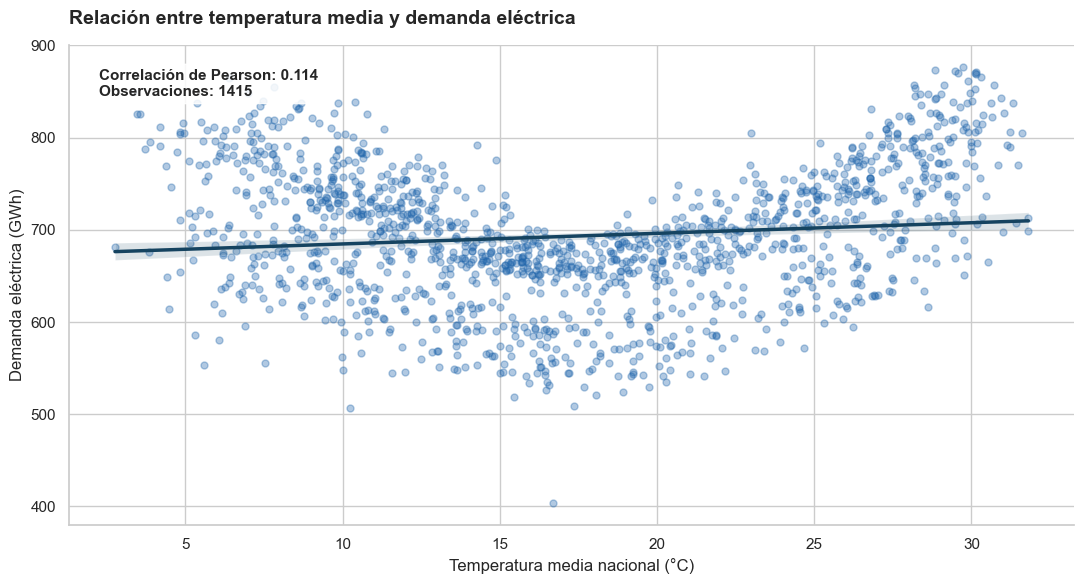

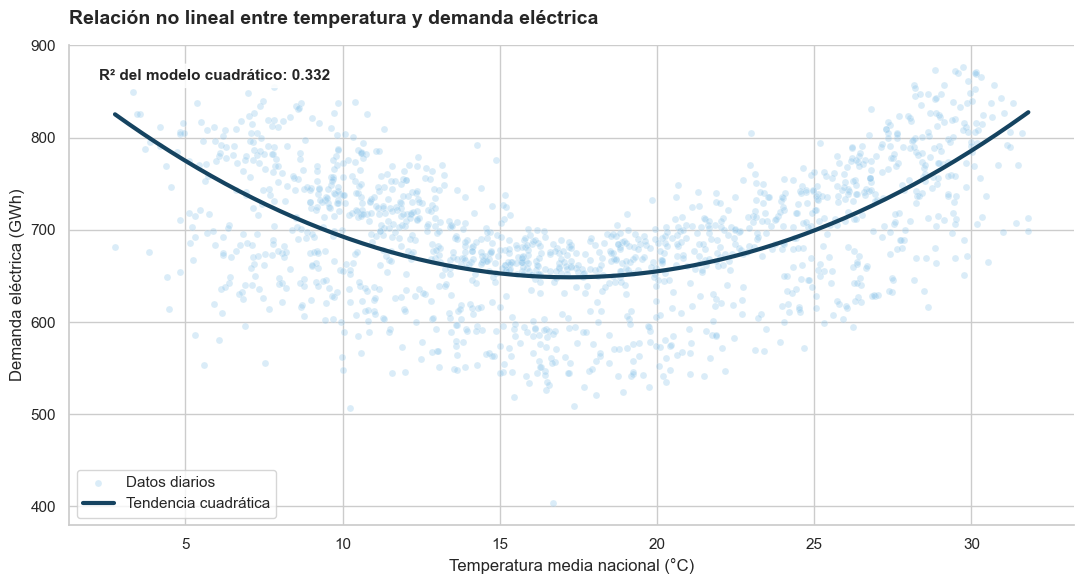

R² del modelo cuadrático: 0.332
Coeficiente cuadrático: 0.8433


In [30]:
# 1. Consultar todos los datos de temperatura y demanda
conexion = sqlite3.connect(rutabbdd)

consulta = """
SELECT
    t.fecha,
    t.t_med,
    d.demanda_gwh
FROM temperatura_nacional AS t
INNER JOIN demanda AS d
    ON t.fecha = d.fecha
WHERE t.t_med IS NOT NULL
  AND d.demanda_gwh IS NOT NULL
ORDER BY t.fecha;
"""

df_correlacion = pd.read_sql_query(consulta, conexion)
conexion.close()

# 2. Preparar los datos
df_correlacion["fecha"] = pd.to_datetime(df_correlacion["fecha"])

df_correlacion = df_correlacion.dropna(
    subset=["t_med", "demanda_gwh"]
)

# 3. Calcular correlación de Pearson
correlacion = df_correlacion["t_med"].corr(
    df_correlacion["demanda_gwh"]
)

print("Número de observaciones:", len(df_correlacion))
print(f"Correlación de Pearson: {correlacion:.3f}")

# 4. Crear gráfico de dispersión con línea de tendencia
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))

sns.regplot(
    data=df_correlacion,
    x="t_med",
    y="demanda_gwh",
    ax=ax,
    color="#2166AC",
    scatter_kws={
        "alpha": 0.35,
        "s": 25
    },
    line_kws={
        "color": "#154360",
        "linewidth": 2.5
    }
)

# 5. Título y etiquetas
ax.set_title(
    "Relación entre temperatura media y demanda eléctrica",
    fontsize=14,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_xlabel("Temperatura media nacional (°C)", fontsize=12)
ax.set_ylabel("Demanda eléctrica (GWh)", fontsize=12)

# 6. Mostrar coeficiente de correlación
ax.text(
    0.03, 0.95,
    f"Correlación de Pearson: {correlacion:.3f}\n"
    f"Observaciones: {len(df_correlacion)}",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)

sns.despine()
plt.tight_layout()
plt.show()


# 1. Preparar los datos
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))

# 2. Gráfico de dispersión
sns.scatterplot(
    data=df_correlacion,
    x="t_med",
    y="demanda_gwh",
    color="#85C1E9",
    alpha=0.30,
    s=25,
    ax=ax,
    label="Datos diarios"
)

# 3. Calcular tendencia cuadrática
import numpy as np

coeficientes = np.polyfit(
    df_correlacion["t_med"],
    df_correlacion["demanda_gwh"],
    2
)

polinomio = np.poly1d(coeficientes)

# Crear valores para dibujar la curva
temperaturas = np.linspace(
    df_correlacion["t_med"].min(),
    df_correlacion["t_med"].max(),
    200
)

demanda_estimada = polinomio(temperaturas)

# 4. Dibujar la curva
ax.plot(
    temperaturas,
    demanda_estimada,
    color="#154360",
    linewidth=3,
    label="Tendencia cuadrática"
)

# 5. Calcular R² del modelo cuadrático
predicciones = polinomio(df_correlacion["t_med"])

ss_res = np.sum(
    (df_correlacion["demanda_gwh"] - predicciones) ** 2
)

ss_tot = np.sum(
    (df_correlacion["demanda_gwh"] -
     df_correlacion["demanda_gwh"].mean()) ** 2
)

r2 = 1 - (ss_res / ss_tot)

# 6. Título y etiquetas
ax.set_title(
    "Relación no lineal entre temperatura y demanda eléctrica",
    fontsize=14,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_xlabel("Temperatura media nacional (°C)", fontsize=12)
ax.set_ylabel("Demanda eléctrica (GWh)", fontsize=12)

# 7. Mostrar R²
ax.text(
    0.03, 0.95,
    f"R² del modelo cuadrático: {r2:.3f}",
    transform=ax.transAxes,
    fontsize=11,
    fontweight="bold",
    verticalalignment="top",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)

ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

print(f"R² del modelo cuadrático: {r2:.3f}")
print(f"Coeficiente cuadrático: {coeficientes[0]:.4f}")


In [31]:
# Temperatura correspondiente al mínimo estimado de demanda
temperatura_minima = -coeficientes[1] / (2 * coeficientes[0])

demanda_minima = polinomio(temperatura_minima)

print(f"Temperatura de mínima demanda: {temperatura_minima:.2f} °C")
print(f"Demanda estimada: {demanda_minima:.2f} GWh")

Temperatura de mínima demanda: 17.24 °C
Demanda estimada: 648.54 GWh


In [32]:
# Comprobar rango real de temperaturas
print("Temperatura mínima observada:",
      df_correlacion["t_med"].min())

print("Temperatura máxima observada:",
      df_correlacion["t_med"].max())

# Comprobar si el vértice está dentro del rango
if df_correlacion["t_med"].min() <= temperatura_minima <= df_correlacion["t_med"].max():
    print("El mínimo estimado está dentro del rango observado.")
else:
    print("El mínimo estimado está fuera del rango observado.")

Temperatura mínima observada: 2.76
Temperatura máxima observada: 31.81
El mínimo estimado está dentro del rango observado.


<h3 style="font-size: 22px;">B1.Saca los cinco días más calurosos (vista `temperatura_nacional`) junto con su demanda. ¿Son también días de mucha demanda? Explica por qué en una o dos frases.</p>


<h3 style="font-size: 20px;">El análisis de correlación lineal de Pearson (0,114) muestra una relación muy débil entre temperatura y demanda eléctrica. Sin embargo, el modelo cuadrático obtiene un R² de 0,332, sugiriendo una relación no lineal. La demanda mínima estimada se sitúa en torno a los 648,54 GWh, cuando la temperatura media nacional alcanza los 17,24 °C. Esto apunta a que las temperaturas extremas, tanto frías como cálidas, pueden incrementar el consumo eléctrico debido a las necesidades de calefacción y refrigeración. </p>

**B2.** Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año.

   anio  solar_twh  total_twh  pct_solar
0  2023      37.45     263.61      14.21
1  2024      44.60     262.43      16.99
2  2025      50.29     272.41      18.46
3  2026      55.41     247.37      22.40


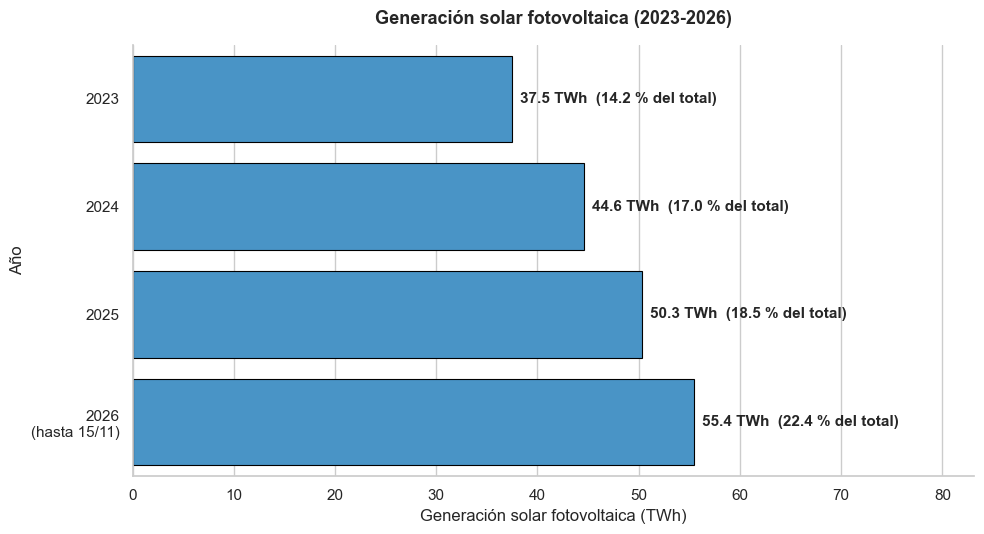

In [33]:
conexion = sqlite3.connect(rutabbdd)

consulta = """
SELECT strftime('%Y', fecha) AS anio,
       ROUND(SUM(CASE WHEN tecnologia = 'Solar fotovoltaica' THEN gwh END) / 1000.0, 2) AS solar_twh,
       ROUND(SUM(gwh) / 1000.0, 2)                                                      AS total_twh,
       ROUND(100.0 * SUM(CASE WHEN tecnologia = 'Solar fotovoltaica' THEN gwh END)
             / SUM(gwh), 2)                                                             AS pct_solar
FROM generacion
GROUP BY anio
ORDER BY anio;
"""

df_solar = pd.read_sql(consulta, conexion)
conexion.close()

print(df_solar)

# Etiqueta del eje Y: el año (2026 está incompleto)
df_solar["anio_etiqueta"] = df_solar["anio"]
df_solar.loc[df_solar["anio"] == "2026", "anio_etiqueta"] = "2026\n(hasta 15/11)"

# Gráfico de barras horizontales: el año en el eje Y
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5.5))

sns.barplot(data=df_solar, x="solar_twh", y="anio_etiqueta", orient="h",
            color="#3498DB", edgecolor="black", linewidth=0.8, ax=ax)

# Valor al final de cada barra: TWh y % sobre el total
for barra, (_, fila) in zip(ax.patches, df_solar.iterrows()):
    ax.text(barra.get_width() + 0.8, barra.get_y() + barra.get_height() / 2,
            f"{fila['solar_twh']:.1f} TWh  ({fila['pct_solar']:.1f} % del total)",
            va="center", fontsize=11, fontweight="bold")

ax.set_title("Generación solar fotovoltaica (2023-2026)",
             fontsize=13, fontweight="bold", loc="center", pad=15)
ax.set_xlabel("Generación solar fotovoltaica (TWh)", fontsize=12)
ax.set_ylabel("Año", fontsize=12)
ax.set_xlim(0, df_solar["solar_twh"].max() * 1.5)
sns.despine()
plt.tight_layout()
plt.show()


<h2 style="font-size: 22px;">B2. Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año.</h2>

<p style="font-size: 20px;">
El gráfico muestra un crecimiento continuo de la generación solar fotovoltaica entre 2023 y 2026.
Su participación en el mix eléctrico aumenta del 14,2 % al 22,4 %, reflejando una mayor presencia de esta energía.
Hay que tener en cuenta que los datos de 2026 son parciales, ya que solo abarcan hasta el 15 de noviembre.
</p>


<h3 style="font-size: 22px;"B2.Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año. </p>


**B3.** ¿Cuántos días de lluvia (1 mm o más) ha tenido cada ciudad? Ordena de más a menos.

      ciudad  dias_lluvia
0     Bilbao          611
1  Barcelona          350
2     Madrid          305
3   Zaragoza          269
4    Sevilla          239
5   Valencia          218


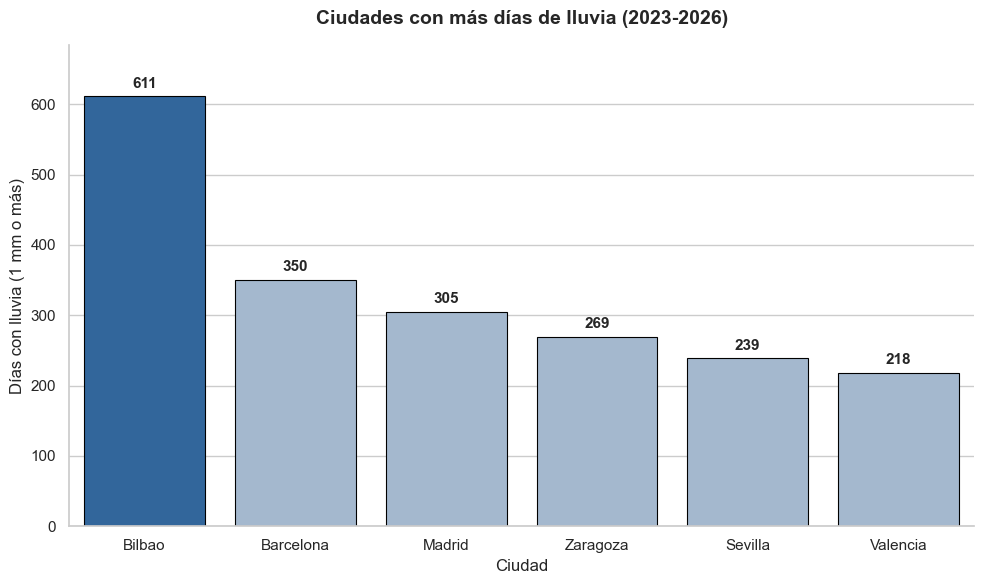

In [34]:
conexion = sqlite3.connect(rutabbdd)

consulta = """
SELECT ciudad,
       COUNT(*) AS dias_lluvia
FROM tiempo
WHERE lluvia_mm >= 1
GROUP BY ciudad
ORDER BY dias_lluvia DESC;
"""

df_lluvia = pd.read_sql(consulta, conexion)
conexion.close()

print(df_lluvia)


# Gráfico de barras (ya vienen ordenadas de más a menos lluvia)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

colores = ["#2166AC"] + ["#9DB7D5"] * (len(df_lluvia) - 1)       # destaca la ciudad con más días
sns.barplot(data=df_lluvia, x="ciudad", y="dias_lluvia", hue="ciudad",
            palette=dict(zip(df_lluvia["ciudad"], colores)), legend=False,
            edgecolor="black", linewidth=0.8, ax=ax)

# Valor encima de cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", padding=4, fontsize=11, fontweight="bold")

mas = df_lluvia.iloc[0]
menos = df_lluvia.iloc[-1]
ax.set_title(
    "Ciudades con más días de lluvia (2023-2026)",
    fontsize=14,
    fontweight="bold",
    loc="center",
    pad=15)
ax.set_xlabel("Ciudad", fontsize=12)
ax.set_ylabel("Días con lluvia (1 mm o más)", fontsize=12)
ax.set_ylim(0, df_lluvia["dias_lluvia"].max() * 1.12)
sns.despine()
plt.tight_layout()
plt.show()



    anio     ciudad  dias_lluvia
0   2023     Bilbao          165
1   2023     Madrid           66
2   2023  Barcelona           63
3   2023   Zaragoza           54
4   2023    Sevilla           50
5   2023   Valencia           41
6   2024     Bilbao          174
7   2024  Barcelona          102
8   2024     Madrid           80
9   2024   Zaragoza           74
10  2024    Sevilla           54
11  2024   Valencia           53
12  2025     Bilbao          150
13  2025  Barcelona          108
14  2025     Madrid           82
15  2025   Zaragoza           79
16  2025    Sevilla           77
17  2025   Valencia           68
18  2026     Bilbao          122
19  2026     Madrid           77
20  2026  Barcelona           77
21  2026   Zaragoza           62
22  2026    Sevilla           58
23  2026   Valencia           56


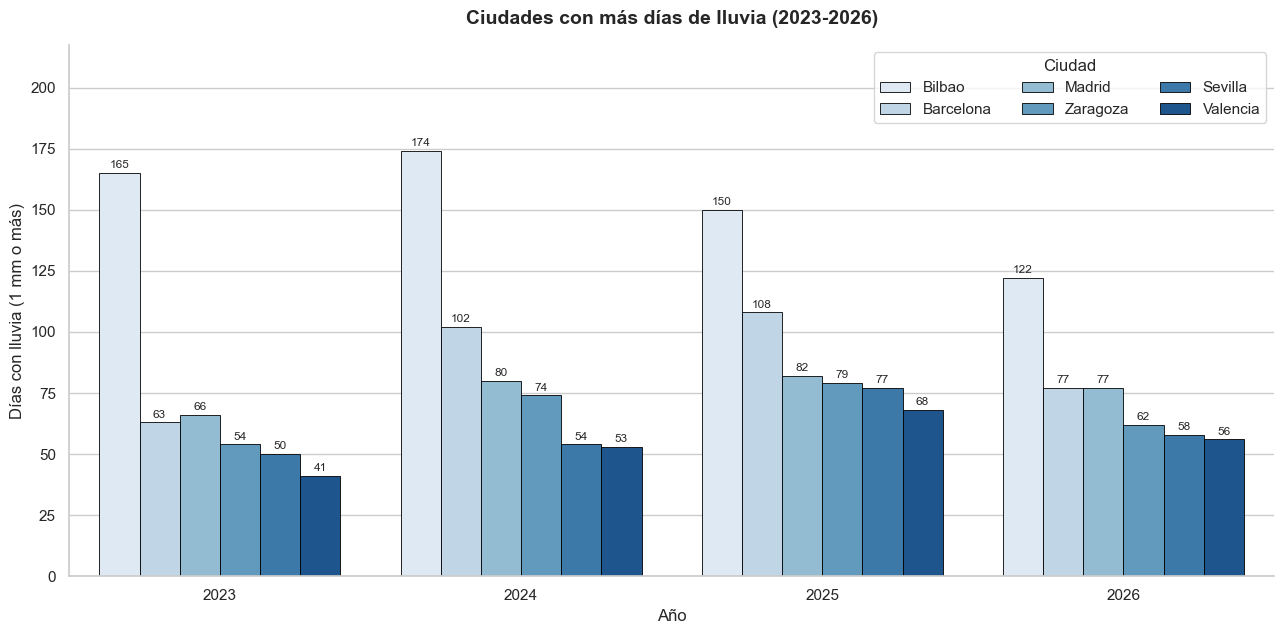

In [35]:
conexion = sqlite3.connect(rutabbdd)
consulta = """
SELECT strftime('%Y', fecha) AS anio,
       ciudad,
       COUNT(*)              AS dias_lluvia
FROM tiempo
WHERE lluvia_mm >= 1
GROUP BY anio, ciudad
ORDER BY anio, dias_lluvia DESC;
"""

df_lluvia_anio = pd.read_sql(consulta, conexion)
conexion.close()
print(df_lluvia_anio)

# Orden de las ciudades según su total (para la leyenda y los colores)
orden_ciudades = (df_lluvia_anio.groupby("ciudad")["dias_lluvia"].sum()
                  .sort_values(ascending=False).index.tolist())

# Gráfico: un grupo de barras por AÑO, una barra por ciudad
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(13, 6.5))

azules = sns.color_palette("Blues", n_colors=len(orden_ciudades))
sns.barplot(
    data=df_lluvia_anio,
    x="anio",
    y="dias_lluvia",
    hue="ciudad",
    hue_order=orden_ciudades,
    palette=azules,
    edgecolor="black",
    linewidth=0.6,
    ax=ax
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", padding=2, fontsize=8.5)

ax.set_title(
    "Ciudades con más días de lluvia (2023-2026)",
    fontsize=14,
    fontweight="bold",
    loc="center",
    pad=15
)

ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Días con lluvia (1 mm o más)", fontsize=12)

ax.legend(title="Ciudad", ncol=3, frameon=True, loc="upper right")
ax.set_ylim(0, df_lluvia_anio["dias_lluvia"].max() * 1.25)

sns.despine()
plt.tight_layout()
plt.show()

<h3 style="font-size: 22px;"> B3.¿Cuántos días de lluvia (1 mm o más) ha tenido cada ciudad?</p>
<h3 style="font-size: 20px;">La Ciudad que tiene mas días de luvia al año es Bilbao,seguido de Barcelona y Madrid.</p>

**Reto (opcional).** Con `LAG`, saca los tres días en que la demanda más subió respecto al día anterior. ¿Qué pasó en el primero?

        fecha  demanda_gwh  demanda_ayer  subida_gwh
0  2025-04-29   590.008854    403.297490  186.711364
1  2026-01-07   849.726680    681.283230  168.443450
2  2023-07-10   778.800770    628.912612  149.888158


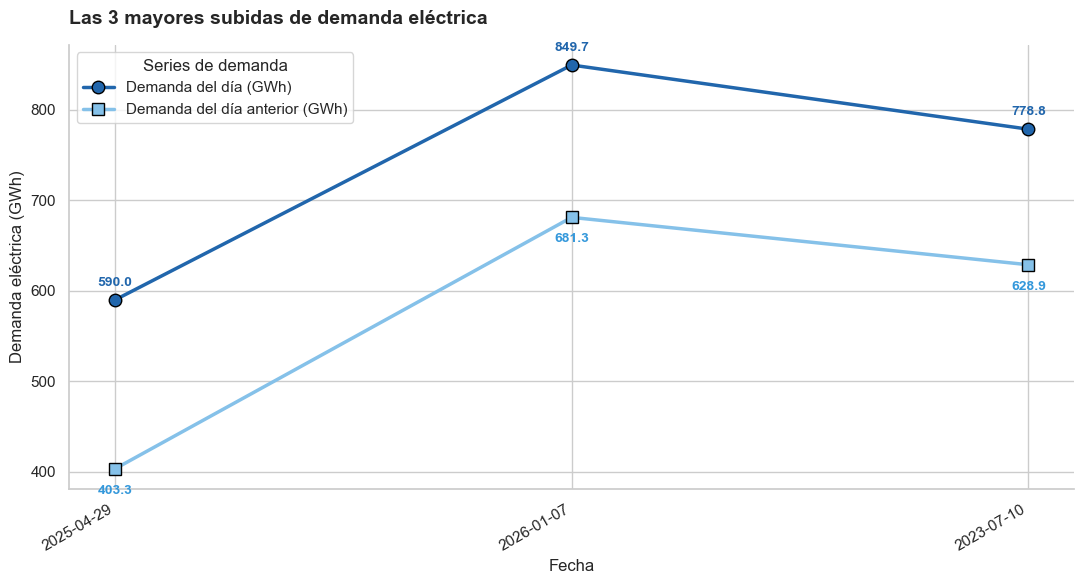

In [36]:
conexion = sqlite3.connect(rutabbdd)

consulta = """
SELECT fecha,
       demanda_gwh,
       LAG(demanda_gwh, 1) OVER (ORDER BY fecha)               AS demanda_ayer,
       demanda_gwh - LAG(demanda_gwh, 1) OVER (ORDER BY fecha) AS subida_gwh
FROM demanda
ORDER BY subida_gwh DESC
LIMIT 3;
"""

df_subidas = pd.read_sql(consulta, conexion)
conexion.close()

print(df_subidas)

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(11, 6))

# Línea 1: Demanda del día
ax.plot(
    df_subidas["fecha"],
    df_subidas["demanda_gwh"],
    color="#2166AC",
    linewidth=2.5,
    marker="o",
    markersize=9,
    markeredgecolor="black",
    label="Demanda del día (GWh)"
)

# Línea 2: Demanda del día anterior
ax.plot(
    df_subidas["fecha"],
    df_subidas["demanda_ayer"],
    color="#85C1E9",
    linewidth=2.5,
    marker="s",
    markersize=9,
    markeredgecolor="black",
    label="Demanda del día anterior (GWh)"
)

# Etiquetas de valores
for i, fila in df_subidas.iterrows():
    ax.annotate(
        f'{fila["demanda_gwh"]:.1f}',
        (fila["fecha"], fila["demanda_gwh"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#2166AC"
    )

    ax.annotate(
        f'{fila["demanda_ayer"]:.1f}',
        (fila["fecha"], fila["demanda_ayer"]),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#3498DB"
    )

# Título y etiquetas
ax.set_title(
    "Las 3 mayores subidas de demanda eléctrica",
    fontsize=14,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_xlabel("Fecha", fontsize=12)
ax.set_ylabel("Demanda eléctrica (GWh)", fontsize=12)

# Leyenda
ax.legend(
    title="Series de demanda",
    loc="best",
    frameon=True
)

# Formato de fechas
fig.autofmt_xdate()

sns.despine()
plt.tight_layout()
plt.show()


<h3 style="font-size: 22px;">Reto (opcional). Con `LAG`, saca los tres días en que la demanda más subió respecto al día anterior. ¿Qué pasó en el primero? .</h3>


<h3 style="font-size: 20px;">El 29 de abril de 2025 fue el día del apagón, el 7 de enero de 2026 fue festivo el día anterior y el 10 de Julio de 2023 fue fin de semana, .</h3>

# Parte C · Excel o Power BI

Esta parte no se hace en el cuaderno. Abre `datos/electricidad_para_panel.xlsx` en Excel o cárgalo en Power BI.

**C1.** Haz una tabla dinámica (en Power BI, una matriz) con la demanda media: los meses en filas y los años en columnas. Hay una celda que no se puede comparar con las demás. ¿Cuál es y por qué? Porque el año 2026 no ha acabado y no hay datos

**C2.** Haz un gráfico de la generación de 2025 por tecnología (hoja `generacion`), ordenado de mayor a menor. Ponle un título que diga la conclusión, no solo el tema.

Entrega una captura de cada una. Puedes pegarlas en un documento o guardarlas como imagen.

# Parte D · Explica (obligatoria)

Contesta con tus palabras. Frases cortas.

D1. Elige una decisión que hayas tenido que tomar en esta prueba y explica por qué la tomaste (4 a 6 líneas).

Decidí realizar un análisis exploratorio de los datos antes de comenzar a trabajar con ellos, para comprobar su calidad y entender mejor la información disponible. También tuve que decidir qué variables analizar y cómo presentar los resultados. Elegí utilizar gráficos y tablas porque permiten visualizar mejor los datos, identificar patrones y facilitar la interpretación de los resultados.

D2. Cuenta tu resultado más interesante a alguien que no sabe de datos (3 líneas).

En los datos analizados de 2026 se observa una elevada demanda eléctrica. En los días de descanso el consumo disminuye, mientras que la generación de energía solar fotovoltaica ha aumentado desde 2023. También he encontrado diferencias en la demanda según las temperaturas y que Bilbao es la ciudad con mayores precipitaciones.

D3. Di un límite de tu análisis, o algo que comprobarías si tuvieras más tiempo.

En el análisis de la relación entre temperatura y demanda eléctrica media, profundizaría en otros factores que pueden influir en el consumo, como la diferencia entre días laborables y días de descanso. Esto permitiría comprobar si el comportamiento de la demanda cambia según el tipo de día y evitar atribuir las variaciones únicamente a la temperatura.

D4. Si has usado una IA, di para qué y cómo comprobaste que el resultado era correcto. Si no la has usado, dilo.

He utilizado herramientas de IA como apoyo para elaborar algunos gráficos y tablas, así como para plantear determinadas consultas SQL. Después he comprobado los resultados ejecutando las consultas en SQLite y contrastando que los datos obtenidos fueran coherentes con el análisis.